# Kasus A: Deteksi Penipuan Pembukaan Rekening Bank

Data: Bank Account Fraud (BAF) varian Base, bulan 0-3. Metrik: TPR pada FPR 5%.

In [1]:
import numpy as np, pandas as pd, lightgbm as lgb
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

SEED = 42
DATA = Path('data/Base.csv')  # unduh dari Kaggle: sgpjesus/bank-account-fraud-dataset-neurips-2022

## 1. Muat data dan ambil bulan 0-3

In [2]:
if not DATA.exists():
    import kagglehub, shutil
    src = kagglehub.dataset_download('sgpjesus/bank-account-fraud-dataset-neurips-2022', path='Base.csv')
    DATA.parent.mkdir(exist_ok=True); shutil.copy(src, DATA)

df = pd.read_csv(DATA)
df = df[df.month.between(0, 3)].reset_index(drop=True)
assert df.month.isin([0, 1, 2, 3]).all()
print(df.shape)
df.groupby('month').fraud_bool.agg(jumlah='size', rasio_fraud='mean')

(547975, 32)


,jumlah,rasio_fraud
month,,
0,132440,0.011326
1,127620,0.009387
2,136979,0.008746
3,150936,0.009222


## 2. Fitur dan preprocessing

- Nilai negatif (-1) berarti data tidak ada (datasheet BAF). Nilai ini **dibiarkan**: tree model bisa memisahkannya, dan ketiadaan data bisa jadi sinyal penipuan.
- `month` bukan fitur, karena model harus berlaku untuk bulan yang belum pernah dilihat.
- Kolom dengan satu nilai saja dibuang.

In [3]:
CAT = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
for c in CAT:
    df[c] = df[c].astype('category')

constant = [c for c in df.columns if df[c].nunique() == 1]
features = [c for c in df.columns if c not in ['fraud_bool', 'month'] + constant]
NUM = [c for c in features if c not in CAT]
assert 'fraud_bool' not in features and 'month' not in features
print('kolom konstan dibuang:', constant)
print(len(features), 'fitur')
(df[NUM] < 0).sum()[lambda s: s > 0].rename('jumlah nilai negatif')

kolom konstan dibuang: ['device_fraud_count']
29 fitur


prev_address_months_count       377557
current_address_months_count      2309
intended_balcon_amount          393220
velocity_6h                          4
credit_risk_score                10973
bank_months_count               136894
session_length_in_minutes          995
device_distinct_emails_8w          226
Name: jumlah nilai negatif, dtype: int64

## 3. Pembagian data: menurut waktu

- **Latih: bulan 0-2. Validasi: bulan 3.**
- Di produksi, model menilai pengajuan yang datang *setelah* data latihnya, dan BAF sengaja menyisipkan pergeseran distribusi antar bulan. Split acak mencampur bulan yang sama ke kedua sisi, sehingga skornya terlalu optimis.
- Pemilihan hyperparameter: latih di bulan 0-1, nilai di bulan 2. Bulan 3 tidak dipakai untuk latih atau tuning; hanya untuk skor akhir, membandingkan LightGBM dengan baseline, dan menentukan ambang.

In [4]:
train, val = df[df.month <= 2], df[df.month == 3]
inner_tr, inner_va = train[train.month <= 1], train[train.month == 2]
assert set(train.month) == {0, 1, 2} and set(val.month) == {3}
y_tr, y_val = train.fraud_bool, val.fraud_bool
print(len(train), len(val))

397039 150936


## 4. Metrik: TPR pada FPR 5%

In [5]:
def tpr_at_fpr(y, score, fpr=0.05):
    f, t, _ = roc_curve(y, score)
    return float(np.interp(fpr, f, t))

def threshold_at_fpr(y, score, fpr=0.05):
    f, _, thr = roc_curve(y, score)
    return float(thr[np.searchsorted(f, fpr, side='right') - 1])

# self-test
rng = np.random.default_rng(SEED)
y_t = rng.integers(0, 2, 200_000)
assert tpr_at_fpr(y_t, y_t) == 1.0
assert abs(tpr_at_fpr(y_t, rng.random(len(y_t))) - 0.05) < 0.01
print('self-test lolos')

self-test lolos


## 5. Baseline: Logistic Regression

Pembanding: one-hot untuk kategori, standarisasi untuk angka. Nilai -1 diperlakukan sebagai angka biasa. Kekuatan regularisasi `C` di-tuning dengan cara yang sama seperti LightGBM: latih di bulan 0-1, nilai di bulan 2, lalu latih ulang di bulan 0-2.

In [6]:
def make_lr(C):
    return make_pipeline(
        ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
                           ('num', StandardScaler(), NUM)]),
        LogisticRegression(C=C, class_weight='balanced', max_iter=2000))

lr_tuning = {C: tpr_at_fpr(inner_va.fraud_bool,
                           make_lr(C).fit(inner_tr[features], inner_tr.fraud_bool).predict_proba(inner_va[features])[:, 1])
             for C in (0.01, 0.1, 1.0, 10.0)}
best_C = max(lr_tuning, key=lr_tuning.get)
print('TPR@5% bulan 2 per C:', {k: round(v, 4) for k, v in lr_tuning.items()}, '-> C =', best_C)

lr = make_lr(best_C).fit(train[features], y_tr)
s_lr = lr.predict_proba(val[features])[:, 1]
res = {'LogisticRegression': (tpr_at_fpr(y_val, s_lr), roc_auc_score(y_val, s_lr))}
res

TPR@5% bulan 2 per C: {0.01: 0.475, 0.1: 0.4741, 1.0: 0.475, 10.0: 0.475} -> C = 0.01


{'LogisticRegression': (0.5186781609195402, 0.8935679840277662)}

## 6. LightGBM

- Cocok untuk data tabel campuran angka dan kategori, cepat, dan membaca kolom kategori langsung.
- Tanpa resampling: TPR@FPR5% hanya bergantung pada urutan skor.
- Grid kecil 12 kombinasi, early stopping di bulan 2.
- Model final dilatih ulang di bulan 0-2 dengan iterasi terbaik × 1.5 (heuristik: data latih 1.5× lebih banyak).

In [7]:
base = dict(objective='binary', learning_rate=0.03, n_estimators=3000, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.7, random_state=SEED, verbose=-1)
grid = [dict(num_leaves=nl, min_child_samples=mcs, reg_lambda=rl)
        for nl in (15, 31, 63) for mcs in (100, 500) for rl in (0, 5)]

tuning = []
for p in grid:
    m = lgb.LGBMClassifier(**base, **p)
    m.fit(inner_tr[features], inner_tr.fraud_bool, eval_X=(inner_va[features],), eval_y=(inner_va.fraud_bool,),
          eval_metric='auc', callbacks=[lgb.early_stopping(200, verbose=False)])
    s = m.predict_proba(inner_va[features], num_iteration=m.best_iteration_)[:, 1]
    tuning.append({**p, 'best_iter': m.best_iteration_, 'tpr@5%_bulan2': tpr_at_fpr(inner_va.fraud_bool, s)})
tuning = pd.DataFrame(tuning).sort_values('tpr@5%_bulan2', ascending=False)
tuning

,num_leaves,min_child_samples,reg_lambda,best_iter,tpr@5%_bulan2
2,15,500,0,490,0.550083
0,15,100,0,448,0.545075
7,31,500,5,374,0.544240
3,15,500,5,654,0.543406
10,63,500,0,251,0.541736
1,15,100,5,537,0.540902
11,63,500,5,247,0.540067
4,31,100,0,316,0.540067
6,31,500,0,288,0.539232
5,31,100,5,329,0.539232


In [8]:
best = tuning.iloc[0]
params = {k: int(best[k]) for k in ('num_leaves', 'min_child_samples', 'reg_lambda')}
# latih ulang di bulan 0-2; data 1.5x lebih banyak, jadi iterasi ditambah proporsional
n_iter = int(best.best_iter * 1.5)
model = lgb.LGBMClassifier(**{**base, 'n_estimators': n_iter}, **params)
model.fit(train[features], y_tr)

s_lgb = model.predict_proba(val[features])[:, 1]
res['LightGBM'] = (tpr_at_fpr(y_val, s_lgb), roc_auc_score(y_val, s_lgb))
THRESHOLD = threshold_at_fpr(y_val, s_lgb)
print(params, 'n_iter =', n_iter, 'threshold@FPR5% =', round(THRESHOLD, 5))
pd.DataFrame(res, index=['TPR@FPR5% (bulan 3)', 'ROC-AUC (bulan 3)']).T.round(4)

{'num_leaves': 15, 'min_child_samples': 500, 'reg_lambda': 0} n_iter = 735 threshold@FPR5% = 0.05603


,TPR@FPR5% (bulan 3),ROC-AUC (bulan 3)
LogisticRegression,0.5187,0.8936
LightGBM,0.5769,0.9142


In [9]:
neg = s_lgb[y_val == 0]
print('FPR aktual pada threshold:', round((neg >= THRESHOLD).mean(), 4))
pd.Series(model.booster_.feature_importance('gain'), index=features).sort_values(ascending=False).head(10)

FPR aktual pada threshold: 0.0498


housing_status                      32360.572907
device_os                           19320.904800
credit_risk_score                   13064.871638
name_email_similarity               12629.154752
current_address_months_count        12587.590083
date_of_birth_distinct_emails_4w     8736.880422
intended_balcon_amount               8722.315613
bank_branch_count_8w                 8670.282089
income                               8361.999517
phone_home_valid                     8036.328689
dtype: float64

## 7. Simpan model dan uji muat ulang

Yang disimpan: model, daftar fitur, kategori tiap kolom, dan ambang skor.

Ambang diambil dari bulan 3 karena itu bulan berlabel terbaru yang **tidak** dilihat model saat latihan (skor model di bulan 0-2 terlalu optimis untuk menentukan ambang). Angka TPR@FPR5% di atas tidak bergantung pada ambang yang disimpan. Di produksi, ambang perlu dikalibrasi ulang tiap bulan karena distribusi bergeser.

In [10]:
import joblib
Path('models').mkdir(exist_ok=True)
bundle = {'model': model, 'features': features,
          'categories': {c: list(df[c].cat.categories) for c in CAT},
          'threshold': THRESHOLD, 'val_tpr_at_fpr5': res['LightGBM'][0]}
joblib.dump(bundle, 'models/lgbm_fraud.joblib')
model.booster_.save_model('models/lgbm_fraud.txt')

loaded = joblib.load('models/lgbm_fraud.joblib')
Xv = val[loaded['features']].copy()
for c, cats in loaded['categories'].items():
    Xv[c] = pd.Categorical(Xv[c], categories=cats)
s_loaded = loaded['model'].predict_proba(Xv)[:, 1]
assert np.allclose(s_loaded, s_lgb)
assert np.allclose(lgb.Booster(model_file='models/lgbm_fraud.txt').predict(Xv), s_lgb)
print('model termuat ulang, skor identik. TPR@FPR5% =', round(tpr_at_fpr(y_val, s_loaded), 4),
      '| ditandai sebagai fraud:', int((s_loaded >= loaded['threshold']).sum()), 'dari', len(Xv))

model termuat ulang, skor identik. TPR@FPR5% = 0.5769 | ditandai sebagai fraud: 8257 dari 150936


## 8. Kurva ROC di bulan 3

Titik merah adalah posisi FPR 5%, tempat TPR dilaporkan.

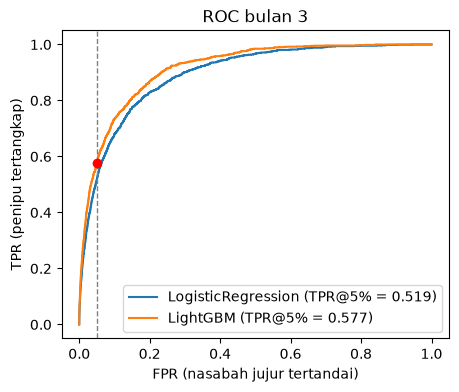

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 4))
for name, s in [('LogisticRegression', s_lr), ('LightGBM', s_lgb)]:
    f, t, _ = roc_curve(y_val, s)
    ax.plot(f, t, label=f'{name} (TPR@5% = {tpr_at_fpr(y_val, s):.3f})')
ax.axvline(0.05, color='gray', ls='--', lw=1)
ax.scatter([0.05], [tpr_at_fpr(y_val, s_lgb)], color='red', zorder=3)
ax.set(xlabel='FPR (nasabah jujur tertandai)', ylabel='TPR (penipu tertangkap)', title='ROC bulan 3')
ax.legend(loc='lower right'); plt.show()

## 9. Contoh pemakaian: memberi skor pengajuan baru

Model dimuat dari file, lalu dipakai untuk menilai beberapa pengajuan tanpa label. Sebagai contoh, dipakai 5 baris pertama bulan 3.

In [12]:
def score_applications(new_df, bundle_path='models/lgbm_fraud.joblib'):
    b = joblib.load(bundle_path)
    X = new_df[b['features']].copy()
    for c, cats in b['categories'].items():
        X[c] = pd.Categorical(X[c], categories=cats)
    score = b['model'].predict_proba(X)[:, 1]
    return pd.DataFrame({'skor_penipuan': score.round(4), 'ditandai': score >= b['threshold']}, index=new_df.index)

baru = pd.read_csv(DATA).query('month == 3').head(5).drop(columns=['fraud_bool'])
score_applications(baru)

,skor_penipuan,ditandai
397039,0.3879,True
397040,0.0005,False
397041,0.0003,False
397042,0.0008,False
397043,0.0023,False


## 10. Ketidakpastian skor dan uji ambang di data terpisah

- **Bootstrap:** bulan 3 di-resample 500 kali untuk interval kepercayaan 95% TPR@FPR5%.
- **Uji ambang:** ambang yang disimpan dihitung dari bulan 3 sendiri. Untuk melihat seberapa stabil ambang antar bulan, model yang dilatih di bulan 0-1 (pengaturan terbaik dari tuning) dipakai untuk menentukan ambang di bulan 2, lalu ambang itu diterapkan ke bulan 3 tanpa diubah.

In [13]:
rng = np.random.default_rng(SEED)
yv = y_val.to_numpy()
boot = []
for _ in range(500):
    idx = rng.integers(0, len(yv), len(yv))
    boot.append(tpr_at_fpr(yv[idx], s_lgb[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'TPR@FPR5% LightGBM bulan 3 = {res["LightGBM"][0]:.4f}, CI 95% bootstrap [{lo:.4f}, {hi:.4f}]')

m_in = lgb.LGBMClassifier(**{**base, 'n_estimators': int(best.best_iter)}, **params).fit(inner_tr[features], inner_tr.fraud_bool)
thr_m2 = threshold_at_fpr(inner_va.fraud_bool, m_in.predict_proba(inner_va[features])[:, 1])
s_m3 = m_in.predict_proba(val[features])[:, 1]
print(f'ambang dari bulan 2 = {thr_m2:.4f} -> di bulan 3: FPR = {(s_m3[yv == 0] >= thr_m2).mean():.4f}, '
      f'TPR = {(s_m3[yv == 1] >= thr_m2).mean():.4f}')

TPR@FPR5% LightGBM bulan 3 = 0.5769, CI 95% bootstrap [0.5504, 0.6026]


ambang dari bulan 2 = 0.0310 -> di bulan 3: FPR = 0.0872, TPR = 0.6997


## 11. Keadilan menurut umur

Paper BAF menilai keadilan dengan membandingkan FPR antar kelompok umur (di bawah 50 dan 50 ke atas): nasabah jujur di satu kelompok sebaiknya tidak lebih sering tertandai. Metrik ini tidak dinilai di tugas, tapi penting untuk model yang menolak calon nasabah.

In [14]:
flag = s_lgb >= THRESHOLD
rows = []
for name, g in [('< 50', val.customer_age < 50), ('>= 50', val.customer_age >= 50)]:
    g = g.to_numpy()
    rows.append({'kelompok umur': name, 'jumlah': int(g.sum()),
                 'FPR': flag[g & (yv == 0)].mean(), 'TPR': flag[g & (yv == 1)].mean()})
fair = pd.DataFrame(rows).set_index('kelompok umur')
print('rasio FPR (kecil / besar) =', round(fair.FPR.min() / fair.FPR.max(), 3))
fair.round(4)

rasio FPR (kecil / besar) = 0.279


,jumlah,FPR,TPR
kelompok umur,,,
< 50,121948,0.0334,0.5170
>= 50,28988,0.1199,0.6566


## 12. Memperbaiki keadilan: ambang per kelompok umur

Skor model tidak diubah. Yang diubah adalah ambangnya: setiap kelompok umur diberi ambang sendiri sehingga FPR masing-masing 5%. Dengan begitu nasabah jujur di kedua kelompok sama-sama paling banyak 5% tertandai, sesuai syarat brief, dan rasio FPR mendekati 1.

Sama seperti ambang global, ambang ini dihitung dari bulan 3 dan perlu dikalibrasi ulang tiap bulan.

In [15]:
AGE_CUT = 50
old = (val.customer_age >= AGE_CUT).to_numpy()
thr_age = {'< 50': threshold_at_fpr(yv[~old], s_lgb[~old]), '>= 50': threshold_at_fpr(yv[old], s_lgb[old])}
flag_fair = np.where(old, s_lgb >= thr_age['>= 50'], s_lgb >= thr_age['< 50'])

rows = []
for name, g in [('< 50', ~old), ('>= 50', old), ('semua', np.ones_like(old))]:
    rows.append({'kelompok umur': name, 'ambang': thr_age.get(name, np.nan),
                 'FPR global': flag[g & (yv == 0)].mean(), 'FPR per-kelompok': flag_fair[g & (yv == 0)].mean(),
                 'TPR global': flag[g & (yv == 1)].mean(), 'TPR per-kelompok': flag_fair[g & (yv == 1)].mean()})
fair2 = pd.DataFrame(rows).set_index('kelompok umur')
r = fair2.loc[['< 50', '>= 50'], 'FPR per-kelompok']
print('rasio FPR sebelum =', round(fair.FPR.min() / fair.FPR.max(), 3), '| sesudah =', round(r.min() / r.max(), 3))
fair2.round(4)

rasio FPR sebelum = 0.279 | sesudah = 0.999


,ambang,FPR global,FPR per-kelompok,TPR global,TPR per-kelompok
kelompok umur,,,,,
< 50,0.0392,0.0334,0.0493,0.5170,0.5912
>= 50,0.1319,0.1199,0.0493,0.6566,0.4472
semua,NaN,0.0498,0.0493,0.5769,0.5295


In [16]:
# simpan ambang per kelompok ke bundle model, lalu pakai saat memberi skor
bundle['threshold_by_age'] = {'cut': AGE_CUT, **thr_age}
joblib.dump(bundle, 'models/lgbm_fraud.joblib')

def flag_fair_applications(new_df, bundle_path='models/lgbm_fraud.joblib'):
    b = joblib.load(bundle_path)
    out = score_applications(new_df, bundle_path)
    t = b['threshold_by_age']
    thr = np.where(new_df.customer_age >= t['cut'], t['>= 50'], t['< 50'])
    out['ditandai_adil'] = out.skor_penipuan.to_numpy() >= thr
    return out

flag_fair_applications(baru).assign(umur=baru.customer_age)

,skor_penipuan,ditandai,ditandai_adil,umur
397039,0.3879,True,True,40
397040,0.0005,False,False,40
397041,0.0003,False,False,30
397042,0.0008,False,False,30
397043,0.0023,False,False,20
